# Finance Analysis — Business Requirements

**Objective:** Analyze the supplied raw customer and finance transaction data in Python according to the Finance Analysis Business Requirements and produce business-ready visualizations.

The requirements cover:
- Overall transaction growth and financial performance
- Monthly transaction amount trends
- Successful / failed / pending transaction amounts
- Customer segment contribution
- State-wise performance
- Transaction type performance using Amount, Fees, Tax and Transaction Count
- Gender-based transaction analysis
- Year-over-Year performance
- Filters for Year, Dynamic Measure, Occupation and Category
- Detailed transaction-level records

**Important:** This notebook uses the raw CSV files as its starting point. It performs cleaning first and then uses the analysis-ready dataset for the business analysis. MySQL loading is intentionally not included yet.

## Cell 1 — Import libraries

We use pandas and NumPy for data preparation and analysis, and Matplotlib for the required business visualizations. The code avoids changing the original raw DataFrames so that raw-versus-cleaned comparisons remain possible.

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 14,
    "axes.labelsize": 10
})

OUTPUT_DIR = "finance_analysis_outputs"
VIS_DIR = os.path.join(OUTPUT_DIR, "visuals")
os.makedirs(VIS_DIR, exist_ok=True)

## Cell 2 — Load the raw customer and transaction files

This cell reads the two supplied CSV files. At this stage we do not clean or transform anything.

The raw data is kept in `customers_raw` and `transactions_raw` so every later transformation can be traced back to the source.

In [6]:
import os
import pandas as pd

folder_path = r"C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\Financial Analysis Dashboard\Raw Data"

def find_file(candidates):
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "Could not find any of these files: " + ", ".join(candidates)
    )

customers_file = find_file([
    os.path.join(folder_path, "customers(1).csv"),
    os.path.join(folder_path, "customers.csv"),
    os.path.join(folder_path, "customers_raw.csv")
])

transactions_file = find_file([
    os.path.join(folder_path, "finance_transactions(1).csv"),
    os.path.join(folder_path, "finance_transactions.csv"),
    os.path.join(folder_path, "finance_transactions_raw.csv")
])

customers_raw = pd.read_csv(customers_file)
transactions_raw = pd.read_csv(transactions_file)

print("Customer file:", customers_file)
print("Transaction file:", transactions_file)
print("Customers:", customers_raw.shape)
print("Transactions:", transactions_raw.shape)

Customer file: C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\Financial Analysis Dashboard\Raw Data\customers.csv
Transaction file: C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\Financial Analysis Dashboard\Raw Data\finance_transactions.csv
Customers: (5000, 11)
Transactions: (50069, 15)


## Cell 3 — Inspect the raw structure

Before cleaning, we inspect the first rows and column names. This is important because the business analysis depends on knowing which fields are actually available in the raw data.

For example, the customer master contains customer segment, occupation, state and gender, while the transaction file contains amount, fee, tax, status and transaction type.

In [7]:
display(customers_raw.head())
display(transactions_raw.head())

print("Customer columns:")
print(customers_raw.columns.tolist())

print("\nTransaction columns:")
print(transactions_raw.columns.tolist())

,customer_id,fisrt_name,second_name,gender,date_of_birth,city,state,occupation,customer_segment,annual_income,join_date
0,C00001,Karan,Chopra,Male,9/10/1982,Kolkata,West Bengal,Retired,SME,"₹988,416.79",15-04-2021
1,C00002,Ishaan,Patel,Male,7/10/1983,Chandigarh,Chandigarh,Salaried,Premium,"₹457,149.28",6/4/2022
2,C00003,Krishna,Patel,Male,27-11-1989,Hyderabad,Telangana,Retired,Retail,"₹378,907.24",6/3/2026
3,C00004,Amit,Verma,Male,13-08-1970,Lucknow,Uttar Pradesh,Salaried,Retail,"₹299,085.16",16-07-2021
4,C00005,Reyansh,Jain,Female,7/2/1977,Ahmedabad,Gujarat,Freelancer,SME,"₹775,436.07",23-02-2023


,transaction_id,transaction_date,account_id,customer_id,transaction_type,channel,merchant_category,amount,fee_amount,tax_amount,currency,transaction_status,is_fraud,risk_score,reference_no
0,T00000001,21-02-2025,A001795,C00629,Investment,Mobile App,Food Delivery,24721.24,123.61,22.25,INR,Success,No,63,REF8835851139
1,T00000002,28-01-2023,A004859,C02038,Transfer,UPI,Groceries,18711.77,93.56,16.84,INR,Success,No,21,REF9409811139
2,T00000003,25-06-2024,A003081,C00652,Transfer,Net Banking,Groceries,45865.90,0.00,0.00,INR,Success,No,25,REF1704628312
3,T00000004,20-02-2025,A004122,C01357,Withdrawal,Auto Debit,Salary,4310.91,NaN,0.78,INR,Failed,No,43,REF3937614748
4,T00000005,08-06-2024,A004150,C02547,Deposit,Branch,Shopping,11646.45,0.00,0.00,INR,Success,No,5,REF5855288886


Customer columns:
['customer_id', 'fisrt_name', 'second_name', 'gender', 'date_of_birth', 'city', 'state', 'occupation', 'customer_segment', 'annual_income', 'join_date']

Transaction columns:
['transaction_id', 'transaction_date', 'account_id', 'customer_id', 'transaction_type', 'channel', 'merchant_category', 'amount', 'fee_amount', 'tax_amount', 'currency', 'transaction_status', 'is_fraud', 'risk_score', 'reference_no']


## Cell 4 — Raw data quality check

This cell checks missing values, exact duplicate rows and duplicate transaction IDs.

These checks matter because the KPIs and transaction counts can be overstated if the same transaction appears more than once.

In [8]:
print("CUSTOMERS — missing values")
display(customers_raw.isnull().sum())
print("Exact duplicate customer rows:", customers_raw.duplicated().sum())

print("\nTRANSACTIONS — missing values")
display(transactions_raw.isnull().sum())
print("Exact duplicate transaction rows:", transactions_raw.duplicated().sum())
print("Duplicate transaction IDs:",
      transactions_raw["transaction_id"].duplicated().sum())

CUSTOMERS — missing values


customer_id         0
fisrt_name          0
second_name         0
gender              0
date_of_birth       0
city                0
state               0
occupation          0
customer_segment    0
annual_income       0
join_date           0
dtype: int64

Exact duplicate customer rows: 0

TRANSACTIONS — missing values


transaction_id         0
transaction_date       0
account_id             0
customer_id            0
transaction_type       0
channel                0
merchant_category      0
amount                 0
fee_amount            24
tax_amount             0
currency               0
transaction_status     0
is_fraud               0
risk_score             0
reference_no           0
dtype: int64

Exact duplicate transaction rows: 68
Duplicate transaction IDs: 69


## Cell 5 — Create the cleaned customer table

We copy the raw customer data and standardize the column names.

Two source column names contain spelling issues:
- `fisrt_name` → `first_name`
- `second_name` → `last_name`

Text fields are trimmed, annual income is converted to numeric, and date fields are converted to proper datetime values.

Duplicate customer IDs are reduced to one customer record because `customer_id` is used as the customer master key.

In [9]:
customers_clean = customers_raw.copy()

customers_clean.columns = (
    customers_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

customers_clean = customers_clean.rename(columns={
    "fisrt_name": "first_name",
    "second_name": "last_name"
})

for col in [
    "first_name", "last_name", "gender", "city",
    "state", "occupation", "customer_segment"
]:
    customers_clean[col] = (
        customers_clean[col].astype("string").str.strip()
    )

customers_clean["annual_income"] = pd.to_numeric(
    customers_clean["annual_income"]
    .astype("string")
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

customers_clean["date_of_birth"] = pd.to_datetime(
    customers_clean["date_of_birth"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

customers_clean["join_date"] = pd.to_datetime(
    customers_clean["join_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Duplicate customer IDs before:",
      customers_clean["customer_id"].duplicated().sum())

customers_clean = customers_clean.drop_duplicates(
    subset="customer_id",
    keep="first"
)

print("Duplicate customer IDs after:",
      customers_clean["customer_id"].duplicated().sum())

Duplicate customer IDs before: 0
Duplicate customer IDs after: 0


## Cell 6 — Create the cleaned transaction table

We standardize transaction column names, convert the transaction date, trim text fields and convert monetary/risk fields to numeric.

The source contains `M@bile App`, which is standardized to `Mobile App`.

We also create:
- `transaction_year`
- `transaction_month_num`
- `transaction_month`

These fields support the monthly and YoY requirements.

In [10]:
transactions_clean = transactions_raw.copy()

transactions_clean.columns = (
    transactions_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

for col in [
    "transaction_type", "channel", "merchant_category",
    "currency", "transaction_status", "reference_no"
]:
    transactions_clean[col] = (
        transactions_clean[col].astype("string").str.strip()
    )

transactions_clean["channel"] = transactions_clean["channel"].replace({
    "M@bile App": "Mobile App"
})

for col in ["amount", "fee_amount", "tax_amount", "risk_score"]:
    transactions_clean[col] = pd.to_numeric(
        transactions_clean[col],
        errors="coerce"
    )

transactions_clean["fee_amount_clean"] = (
    transactions_clean["fee_amount"].fillna(0)
)

transactions_clean["transaction_year"] = (
    transactions_clean["transaction_date"].dt.year
)

transactions_clean["transaction_month_num"] = (
    transactions_clean["transaction_date"].dt.month
)

transactions_clean["transaction_month"] = (
    transactions_clean["transaction_date"].dt.strftime("%B")
)

transactions_clean["is_negative_amount"] = (
    transactions_clean["amount"] < 0
)

transactions_clean["is_missing_fee"] = (
    transactions_clean["fee_amount"].isna()
)

## Cell 7 — Remove duplicate transaction IDs for the analysis dataset

The raw file contains duplicated transaction IDs. Because the business KPI is based on transactions, the analysis uses one record per `transaction_id`.

We do **not** remove negative amounts. Negative amounts may represent legitimate reversals/refunds, and the business requirements do not say to exclude them. Instead, they are retained and flagged.

In [11]:
print("Duplicate transaction IDs before:",
      transactions_clean["transaction_id"].duplicated().sum())

analysis_tx = transactions_clean.drop_duplicates(
    subset="transaction_id",
    keep="first"
).copy()

print("Analysis-ready rows:", len(analysis_tx))
print("Duplicate transaction IDs after:",
      analysis_tx["transaction_id"].duplicated().sum())

print("Negative amount rows retained:",
      analysis_tx["is_negative_amount"].sum())

Duplicate transaction IDs before: 69
Analysis-ready rows: 50000
Duplicate transaction IDs after: 0
Negative amount rows retained: 8


## Cell 8 — Validate the customer-to-transaction relationship

The transaction table contains `customer_id`, while demographic attributes such as segment, gender, occupation and state live in the customer master.

This validation checks whether every transaction customer exists in the customer master before we use joins for the business analysis.

In [12]:
missing_customer_records = analysis_tx[
    ~analysis_tx["customer_id"].isin(customers_clean["customer_id"])
]

print(
    "Transactions with customer IDs missing from customer master:",
    len(missing_customer_records)
)

display(missing_customer_records.head())

Transactions with customer IDs missing from customer master: 0


,transaction_id,transaction_date,account_id,customer_id,transaction_type,channel,merchant_category,amount,fee_amount,tax_amount,...,transaction_status,is_fraud,risk_score,reference_no,fee_amount_clean,transaction_year,transaction_month_num,transaction_month,is_negative_amount,is_missing_fee


In [14]:
customers_clean

,customer_id,first_name,last_name,gender,date_of_birth,city,state,occupation,customer_segment,annual_income,join_date
0,C00001,Karan,Chopra,Male,1982-10-09,Kolkata,West Bengal,Retired,SME,988416.79,2021-04-15
1,C00002,Ishaan,Patel,Male,1983-10-07,Chandigarh,Chandigarh,Salaried,Premium,457149.28,2022-04-06
2,C00003,Krishna,Patel,Male,1989-11-27,Hyderabad,Telangana,Retired,Retail,378907.24,2026-03-06
3,C00004,Amit,Verma,Male,1970-08-13,Lucknow,Uttar Pradesh,Salaried,Retail,299085.16,2021-07-16
4,C00005,Reyansh,Jain,Female,1977-02-07,Ahmedabad,Gujarat,Freelancer,SME,775436.07,2023-02-23
...,...,...,...,...,...,...,...,...,...,...,...
4995,C04996,Pari,Kapoor,Male,2002-11-06,Hyderabad,Telangana,Business Owner,Retail,279631.8,2021-11-06
4996,C04997,Rohan,Malhotra,Female,1975-01-01,Bhopal,Madhya Pradesh,Business Owner,Retail,869312.76,2022-07-20
4997,C04998,Ira,Agarwal,Female,1976-12-10,Lucknow,Uttar Pradesh,Self Employed,Premium,3571015.01,2021-04-03
4998,C04999,Sneha,Joshi,Female,1994-04-03,Kochi,Kerala,Salaried,SME,1046872.92,2023-07-28


In [15]:
transactions_clean

,transaction_id,transaction_date,account_id,customer_id,transaction_type,channel,merchant_category,amount,fee_amount,tax_amount,...,transaction_status,is_fraud,risk_score,reference_no,fee_amount_clean,transaction_year,transaction_month_num,transaction_month,is_negative_amount,is_missing_fee
0,T00000001,2025-02-21,A001795,C00629,Investment,Mobile App,Food Delivery,24721.24,123.61,22.25,...,Success,No,63,REF8835851139,123.61,2025,2,February,False,False
1,T00000002,2023-01-28,A004859,C02038,Transfer,UPI,Groceries,18711.77,93.56,16.84,...,Success,No,21,REF9409811139,93.56,2023,1,January,False,False
2,T00000003,2024-06-25,A003081,C00652,Transfer,Net Banking,Groceries,45865.90,0.00,0.00,...,Success,No,25,REF1704628312,0.00,2024,6,June,False,False
3,T00000004,2025-02-20,A004122,C01357,Withdrawal,Auto Debit,Salary,4310.91,NaN,0.78,...,Failed,No,43,REF3937614748,0.00,2025,2,February,False,True
4,T00000005,2024-06-08,A004150,C02547,Deposit,Branch,Shopping,11646.45,0.00,0.00,...,Success,No,5,REF5855288886,0.00,2024,6,June,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50064,T00049879,2024-01-09,A006793,C02066,Transfer,Net Banking,Shopping,11386.50,22.77,4.10,...,Success,No,31,REF6074582257,22.77,2024,1,January,False,False
50065,T00049880,2025-06-27,A003754,C01053,Loan EMI,ATM,Entertainment,40959.94,81.92,14.75,...,Success,No,17,REF4636170490,81.92,2025,6,June,False,False
50066,T00049881,2024-02-08,A003657,C02434,Loan EMI,ATM,Education,9873.84,9.87,1.78,...,Success,No,56,REF6815460792,9.87,2024,2,February,False,False
50067,T00049882,2023-11-13,A003840,C03287,Transfer,UPI,Salary,13980.12,0.00,0.00,...,Success,No,67,REF4683694384,0.00,2023,11,November,False,False


## Cell 9 — Define the analysis year

The dashboard screenshot is filtered to 2025, so 2025 is used as the main analysis year.

The supplied data also contains 2026 records, but 2026 is a partial year. Therefore the primary YoY comparison is 2025 versus 2024.

In [13]:
ANALYSIS_YEAR = 2025

year_data = analysis_tx[
    analysis_tx["transaction_year"] == ANALYSIS_YEAR
].copy()

previous_year_data = analysis_tx[
    analysis_tx["transaction_year"] == ANALYSIS_YEAR - 1
].copy()

print("Analysis year:", ANALYSIS_YEAR)
print("2025 rows:", len(year_data))
print("2024 rows:", len(previous_year_data))

Analysis year: 2025
2025 rows: 14944
2024 rows: 15029


# KPI Analysis

## Cell 10 — Calculate the five required KPIs

The business requirements specify:
1. Total Amount
2. Total Transactions
3. Average Transaction Value
4. Total Fees
5. Total Tax

The calculations below are performed on the analysis-ready transaction table.

In [16]:
kpis = pd.DataFrame({
    "KPI": [
        "Total Amount",
        "Total Transactions",
        "Average Transaction Value",
        "Total Fees",
        "Total Tax"
    ],
    "Value": [
        year_data["amount"].sum(),
        year_data["transaction_id"].count(),
        year_data["amount"].mean(),
        year_data["fee_amount_clean"].sum(),
        year_data["tax_amount"].sum()
    ]
})

display(kpis)

,KPI,Value
0,Total Amount,1.374858e+08
1,Total Transactions,1.494400e+04
2,Average Transaction Value,9.200069e+03
3,Total Fees,2.168706e+05
4,Total Tax,3.904110e+04


## Cell 11 — Calculate YoY KPI changes

The business requirements ask for YoY performance. This cell compares each 2025 KPI with 2024.

The percentage formula is:

`(Current Year - Previous Year) / Previous Year × 100`

This separates transaction-value growth from transaction-volume growth.

In [17]:
def yoy_change(current, previous):
    return ((current - previous) / previous) * 100

current_values = {
    "Total Amount": year_data["amount"].sum(),
    "Total Transactions": len(year_data),
    "Average Transaction Value": year_data["amount"].mean(),
    "Total Fees": year_data["fee_amount_clean"].sum(),
    "Total Tax": year_data["tax_amount"].sum()
}

previous_values = {
    "Total Amount": previous_year_data["amount"].sum(),
    "Total Transactions": len(previous_year_data),
    "Average Transaction Value": previous_year_data["amount"].mean(),
    "Total Fees": previous_year_data["fee_amount_clean"].sum(),
    "Total Tax": previous_year_data["tax_amount"].sum()
}

yoy_table = pd.DataFrame({
    "2024": previous_values,
    "2025": current_values
})

yoy_table["YoY %"] = [
    yoy_change(current_values[k], previous_values[k])
    for k in yoy_table.index
]

display(yoy_table)

,2024,2025,YoY %
Total Amount,1.355528e+08,1.374858e+08,1.426017
Total Transactions,1.502900e+04,1.494400e+04,-0.565573
Average Transaction Value,9.019417e+03,9.200069e+03,2.002918
Total Fees,2.171568e+05,2.168706e+05,-0.131803
Total Tax,3.914277e+04,3.904110e+04,-0.259741


# 1. Total Amount by Month

## Cell 12 — Monthly transaction amount

The requirements specify a line or area chart to identify seasonal spikes and drops.

The month number is used for sorting so the chart remains January through December rather than alphabetical order.

In [18]:
monthly_amount = (
    year_data
    .groupby(["transaction_month_num", "transaction_month"], as_index=False)
    ["amount"].sum()
    .sort_values("transaction_month_num")
)

display(monthly_amount)

,transaction_month_num,transaction_month,amount
0,1,January,11108360.31
1,2,February,10718275.10
2,3,March,11330439.91
3,4,April,11432437.83
4,5,May,12185663.44
5,6,June,11862120.44
6,7,July,12508617.19
7,8,August,11618973.42
8,9,September,10957043.16
9,10,October,10409892.97


## Cell 13 — Visualize monthly amount trend

This visualization directly implements the required Total Amount by Month chart.

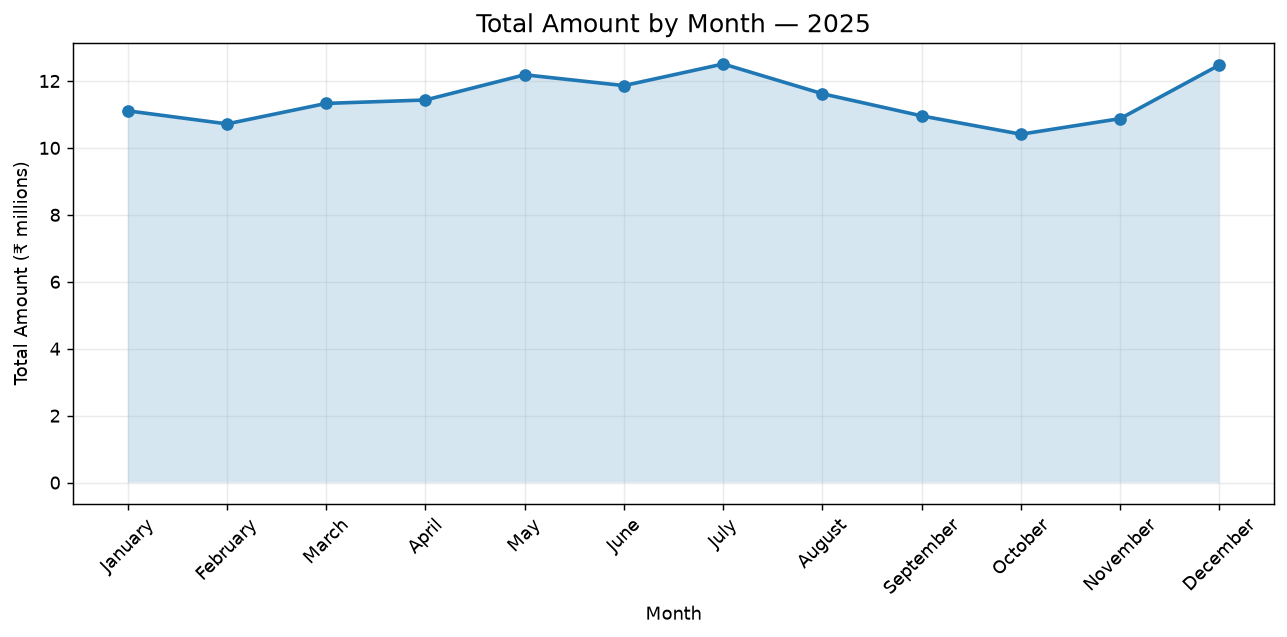

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_amount["transaction_month"],
    monthly_amount["amount"] / 1e6,
    marker="o",
    linewidth=2
)

ax.fill_between(
    range(len(monthly_amount)),
    monthly_amount["amount"] / 1e6,
    alpha=0.18
)

ax.set_title(f"Total Amount by Month — {ANALYSIS_YEAR}")
ax.set_xlabel("Month")
ax.set_ylabel("Total Amount (₹ millions)")
ax.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "01_total_amount_by_month.png"),
    bbox_inches="tight"
)

plt.show()

# 2. Total Amount by Transaction Status

## Cell 14 — Status aggregation

The requirements call for Success, Failed and Pending transaction amounts.

This aggregation calculates both total amount and transaction count so operational performance can be evaluated from both perspectives.

In [20]:
status_analysis = (
    year_data
    .groupby("transaction_status")
    .agg(
        total_amount=("amount", "sum"),
        transactions=("transaction_id", "count")
    )
    .sort_values("total_amount", ascending=False)
)

display(status_analysis)

,total_amount,transactions
transaction_status,,
Success,1.173716e+08,12829
Failed,1.435409e+07,1514
Pending,5.760092e+06,601


## Cell 15 — Status donut chart

A donut chart is used because the requirement specifically asks for a part-to-whole comparison of transaction amount by status.

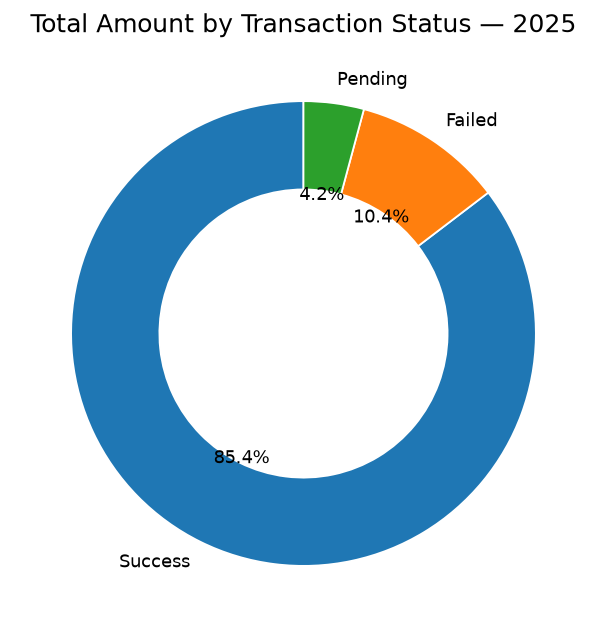

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    status_analysis["total_amount"],
    labels=status_analysis.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.38, "edgecolor": "white"}
)

ax.set_title(f"Total Amount by Transaction Status — {ANALYSIS_YEAR}")
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "02_total_amount_by_status.png"),
    bbox_inches="tight"
)

plt.show()

# 3. Total Amount by Customer Segment

## Cell 16 — Join transactions to customer segments

Customer segment is stored in the customer master, so transactions are joined to `customers_clean` using `customer_id`.

The required segments are Retail, Premium, SME, Corporate and Wealth.

In [22]:
segment_data = (
    year_data
    .merge(
        customers_clean[["customer_id", "customer_segment"]],
        on="customer_id",
        how="left"
    )
)

segment_analysis = (
    segment_data
    .groupby("customer_segment")
    .agg(
        total_amount=("amount", "sum"),
        transactions=("transaction_id", "count")
    )
    .sort_values("total_amount", ascending=False)
)

display(segment_analysis)

,total_amount,transactions
customer_segment,,
Retail,75681024.33,8133
Premium,25638295.37,2776
SME,21096182.18,2365
Corporate,9055849.88,1028
Wealth,6014476.98,642


## Cell 17 — Customer segment horizontal bar

The horizontal bar chart makes the segment ranking easy to compare.

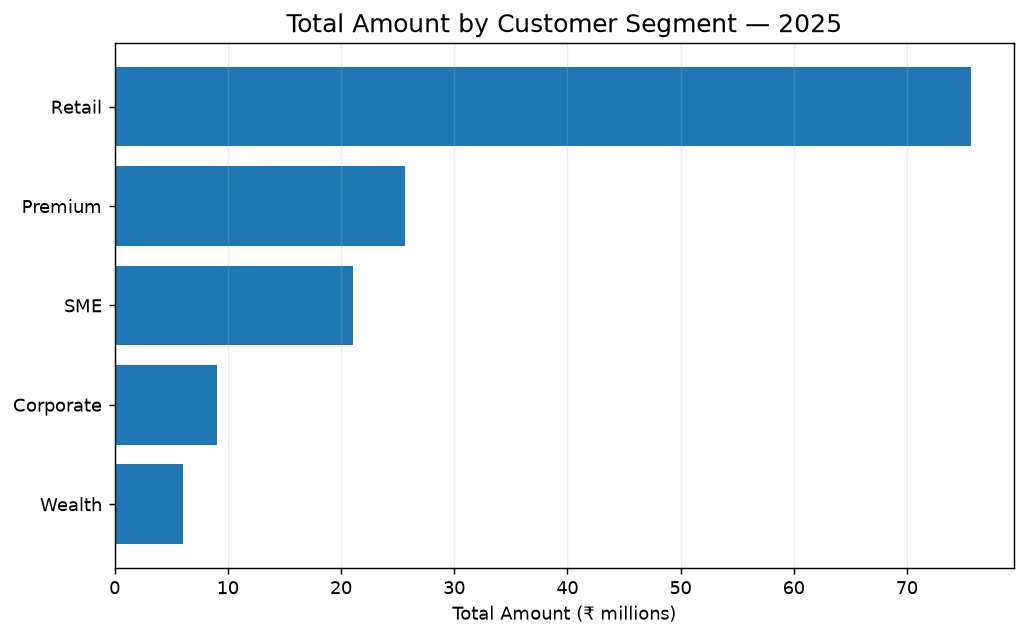

In [23]:
plot_data = segment_analysis.sort_values("total_amount")

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    plot_data.index,
    plot_data["total_amount"] / 1e6
)

ax.set_title(f"Total Amount by Customer Segment — {ANALYSIS_YEAR}")
ax.set_xlabel("Total Amount (₹ millions)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "03_total_amount_by_customer_segment.png"),
    bbox_inches="tight"
)

plt.show()

# 4. Total Amount by State

## Cell 18 — State-wise aggregation

State also comes from the customer master. We join the transaction data to the customer table and aggregate transaction amount by state.

In [24]:
state_data = (
    year_data
    .merge(
        customers_clean[["customer_id", "state"]],
        on="customer_id",
        how="left"
    )
)

state_analysis = (
    state_data
    .groupby("state")
    .agg(
        total_amount=("amount", "sum"),
        transactions=("transaction_id", "count")
    )
    .sort_values("total_amount", ascending=False)
)

display(state_analysis)

,total_amount,transactions
state,,
Maharashtra,21806561.30,2271
Karnataka,15926476.15,1757
Gujarat,15376884.51,1696
Tamil Nadu,13825257.36,1457
Uttar Pradesh,13163034.20,1393
Madhya Pradesh,11966145.20,1388
Haryana,7622756.21,751
Kerala,6994088.87,793
Delhi,6812555.66,797


## Cell 19 — State horizontal bar

The requirement specifies a horizontal bar chart to compare state-level performance.

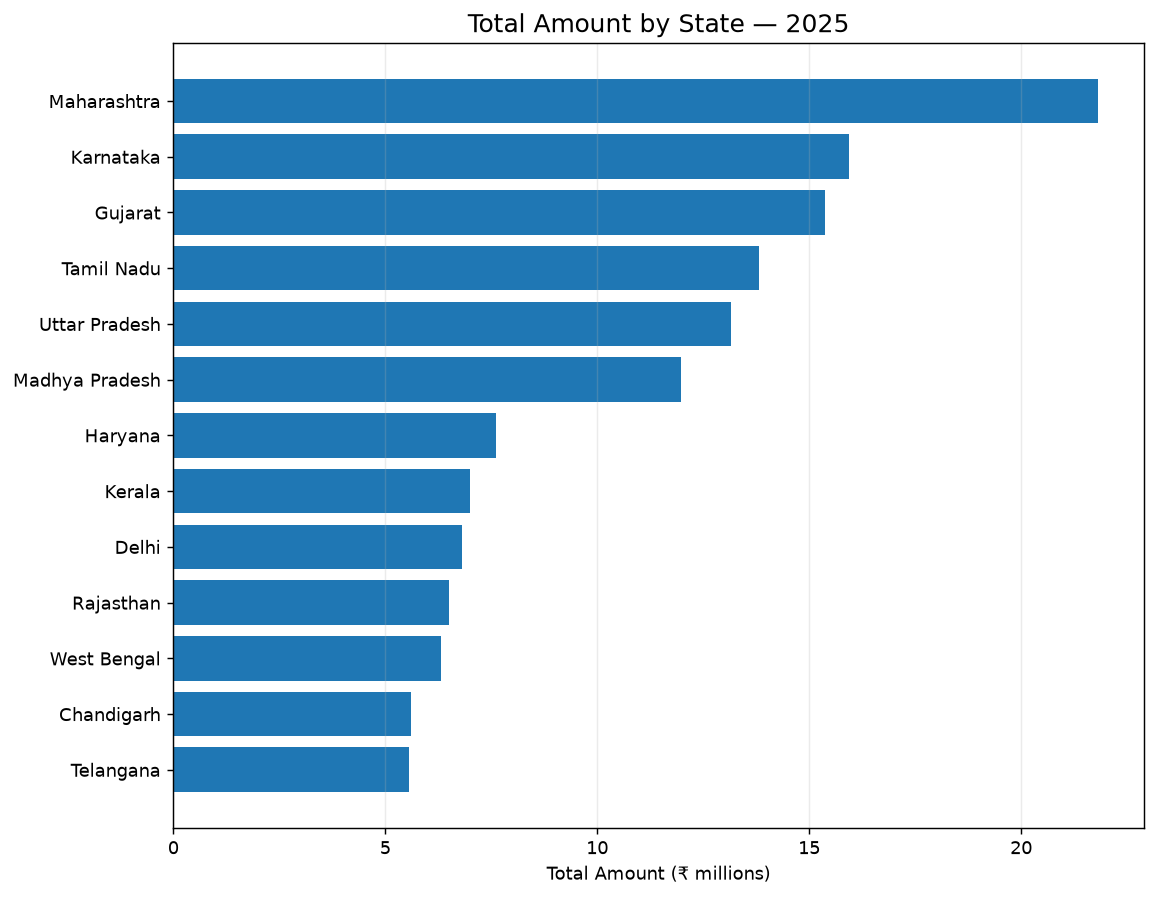

In [25]:
plot_data = state_analysis.sort_values("total_amount")

fig, ax = plt.subplots(figsize=(9, 7))

ax.barh(
    plot_data.index,
    plot_data["total_amount"] / 1e6
)

ax.set_title(f"Total Amount by State — {ANALYSIS_YEAR}")
ax.set_xlabel("Total Amount (₹ millions)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "04_total_amount_by_state.png"),
    bbox_inches="tight"
)

plt.show()

# 5. Transaction Type Analysis

## Cell 20 — Build the transaction type matrix

The requirements specify a matrix/heatmap with:
- Amount
- Fees
- Tax
- Transactions Count

The aggregation below produces exactly those four measures for each transaction type.

In [26]:
transaction_type_analysis = (
    year_data
    .groupby("transaction_type")
    .agg(
        Amount=("amount", "sum"),
        Fees=("fee_amount_clean", "sum"),
        Tax=("tax_amount", "sum"),
        Transactions=("transaction_id", "count")
    )
    .sort_values("Amount", ascending=False)
)

display(transaction_type_analysis)

,Amount,Fees,Tax,Transactions
transaction_type,,,,
Loan EMI,39989086.45,64028.92,11525.18,2771
Transfer,36169194.57,55331.16,9959.58,2450
Deposit,20293697.30,34465.02,6203.67,1483
Investment,15054522.23,22901.97,4122.27,1080
Card Payment,8170484.95,13013.47,2342.26,1603
Withdrawal,6604525.76,9954.67,1792.54,1293
Bill Payment,6446604.92,9726.28,1754.19,1258
Interest Credit,2729347.99,4241.66,763.39,1208
Refund,1483171.50,2286.75,412.15,677


## Cell 21 — Transaction type heatmap

The four measures have different units and magnitudes. Therefore the heatmap normalizes each column for color intensity while displaying the actual value inside each cell.

This makes it possible to visually compare relative performance without changing the underlying business numbers.

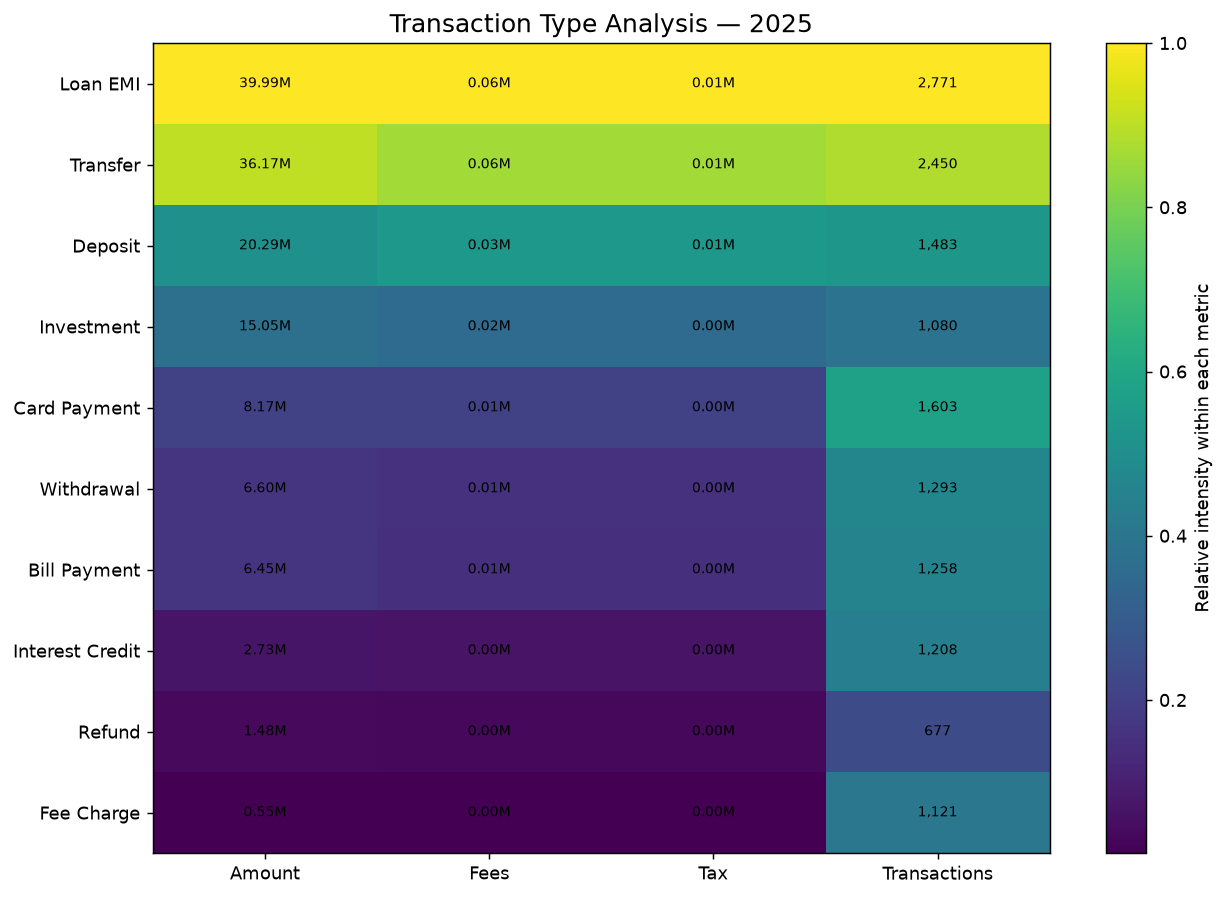

In [27]:
heatmap_data = transaction_type_analysis.copy()

for col in heatmap_data.columns:
    max_value = heatmap_data[col].max()
    if max_value != 0:
        heatmap_data[col] = heatmap_data[col] / max_value

fig, ax = plt.subplots(figsize=(10, 7))

image = ax.imshow(
    heatmap_data.values,
    aspect="auto"
)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_title(f"Transaction Type Analysis — {ANALYSIS_YEAR}")

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        actual_value = transaction_type_analysis.iloc[i, j]
        label = (
            f"{actual_value / 1e6:.2f}M"
            if j < 3
            else f"{int(actual_value):,}"
        )
        ax.text(
            j, i, label,
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(
    image,
    ax=ax,
    label="Relative intensity within each metric"
)

plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "05_transaction_type_heatmap.png"),
    bbox_inches="tight"
)

plt.show()

# 6. Total Amount by Gender

## Cell 22 — Gender aggregation

Gender is obtained from the customer master and joined to the transaction data.

The requirement specifically asks for Male and Female transaction-value contribution.

In [28]:
gender_data = (
    year_data
    .merge(
        customers_clean[["customer_id", "gender"]],
        on="customer_id",
        how="left"
    )
)

gender_analysis = (
    gender_data
    .groupby("gender")
    .agg(
        total_amount=("amount", "sum"),
        transactions=("transaction_id", "count")
    )
    .sort_values("total_amount", ascending=False)
)

display(gender_analysis)

,total_amount,transactions
gender,,
Female,72574193.12,7770
Male,64911635.62,7174


## Cell 23 — Gender donut chart

The donut chart shows the share of total transaction amount by gender.

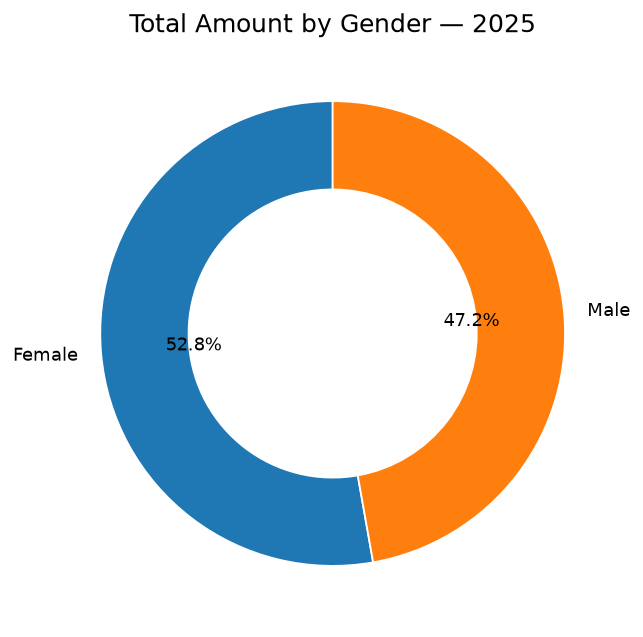

In [29]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    gender_analysis["total_amount"],
    labels=gender_analysis.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.38, "edgecolor": "white"}
)

ax.set_title(f"Total Amount by Gender — {ANALYSIS_YEAR}")
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "06_total_amount_by_gender.png"),
    bbox_inches="tight"
)

plt.show()

# 7. Year-over-Year Total Amount Trend

## Cell 24 — Annual performance table

The requirements call for YoY performance changes. This table calculates annual transaction amount, transaction count and average transaction value.

2026 is retained for data awareness but should not be interpreted as a full-year comparison because the supplied data is partial.

In [30]:
annual_analysis = (
    analysis_tx
    .groupby("transaction_year")
    .agg(
        total_amount=("amount", "sum"),
        total_transactions=("transaction_id", "count"),
        average_transaction_value=("amount", "mean"),
        total_fees=("fee_amount_clean", "sum"),
        total_tax=("tax_amount", "sum")
    )
    .sort_index()
)

display(annual_analysis)

,total_amount,total_transactions,average_transaction_value,total_fees,total_tax
transaction_year,,,,,
2023,1.370284e+08,15034,9114.565398,216453.38,38978.20
2024,1.355528e+08,15029,9019.417291,217156.78,39142.77
2025,1.374858e+08,14944,9200.068840,216870.56,39041.10
2026,4.532411e+07,4993,9077.531298,75413.00,13574.28


## Cell 25 — YoY amount visualization

This line chart shows the progression of total transaction amount by year. The 2025 versus 2024 comparison is the main completed-year YoY analysis.

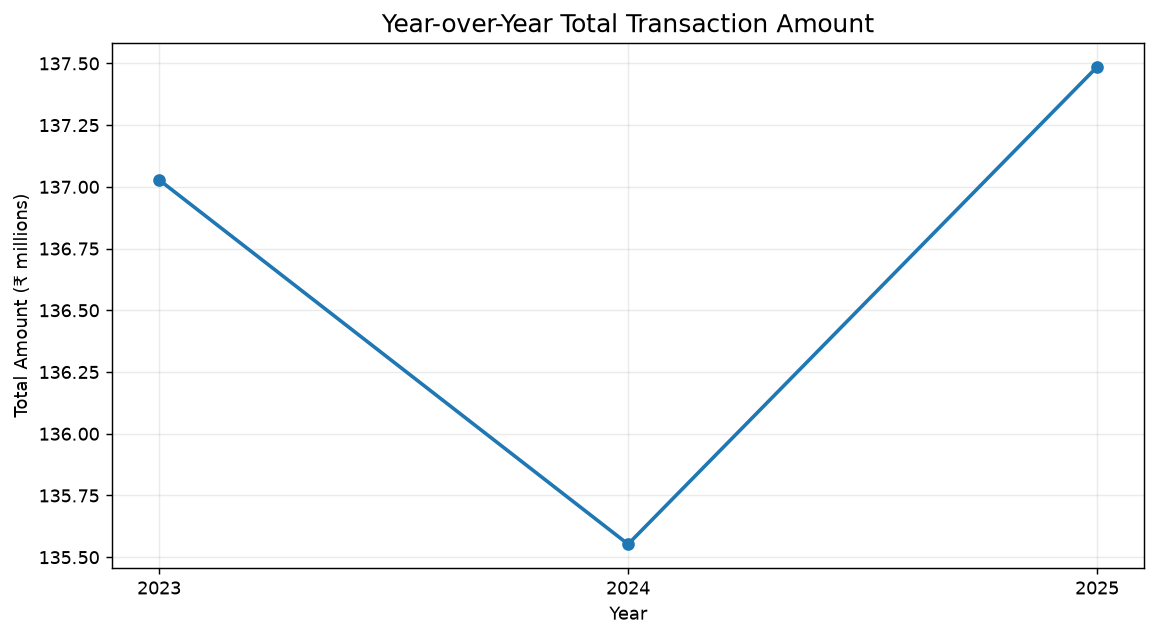

In [31]:
yoy_plot = annual_analysis.loc[
    annual_analysis.index <= ANALYSIS_YEAR
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    yoy_plot.index.astype(str),
    yoy_plot["total_amount"] / 1e6,
    marker="o",
    linewidth=2
)

ax.set_title("Year-over-Year Total Transaction Amount")
ax.set_xlabel("Year")
ax.set_ylabel("Total Amount (₹ millions)")
ax.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "07_yoy_total_amount.png"),
    bbox_inches="tight"
)

plt.show()

# 8. Monthly Transaction Count

## Cell 26 — Transaction volume trend

Although the main chart requirement is monthly amount, transaction count is useful for explaining whether an amount spike came from more transactions or larger transactions.

In [32]:
monthly_count = (
    year_data
    .groupby(["transaction_month_num", "transaction_month"], as_index=False)
    ["transaction_id"].count()
    .sort_values("transaction_month_num")
)

display(monthly_count)

,transaction_month_num,transaction_month,transaction_id
0,1,January,1247
1,2,February,1168
2,3,March,1281
3,4,April,1234
4,5,May,1252
5,6,June,1259
6,7,July,1320
7,8,August,1293
8,9,September,1258
9,10,October,1160


## Cell 27 — Monthly transaction count visualization

This supporting visualization helps interpret monthly transaction activity alongside the required monthly amount chart.

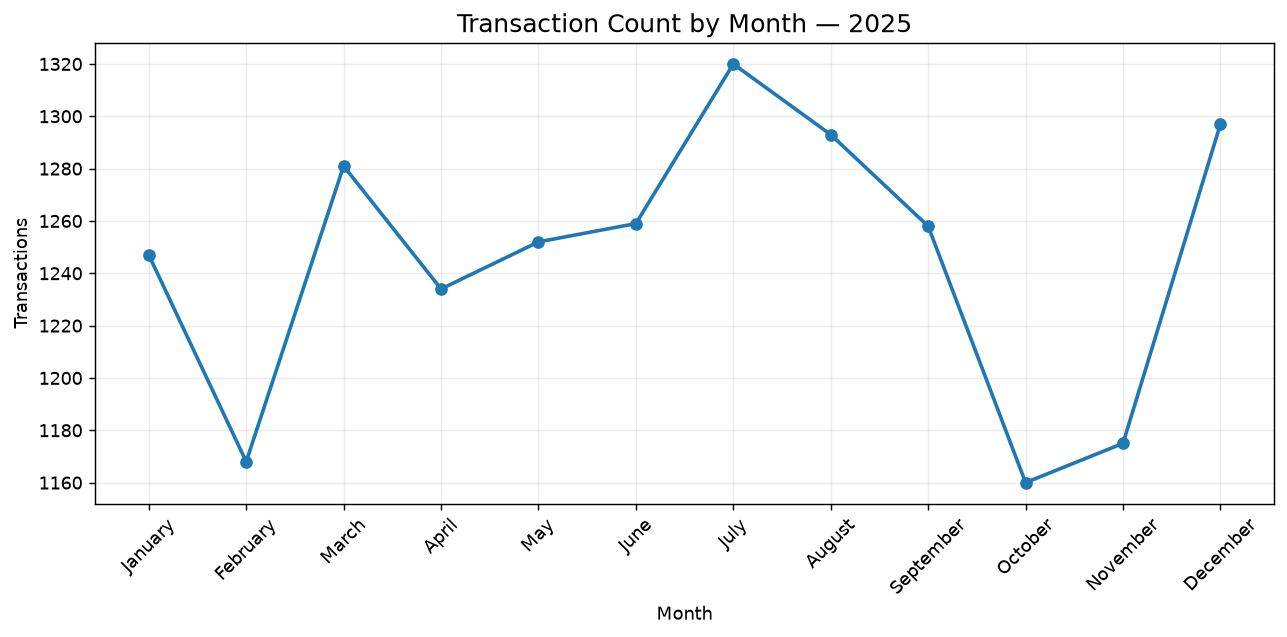

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_count["transaction_month"],
    monthly_count["transaction_id"],
    marker="o",
    linewidth=2
)

ax.set_title(f"Transaction Count by Month — {ANALYSIS_YEAR}")
ax.set_xlabel("Month")
ax.set_ylabel("Transactions")
ax.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(VIS_DIR, "08_transaction_count_by_month.png"),
    bbox_inches="tight"
)

plt.show()

# 9. Dashboard Filter Logic

The Power BI dashboard provides filters for **Year, Dynamic Measure, Occupation and Category**.

For the Python version:
- Year → `transaction_year`
- Dynamic Measure → amount / fee / tax / transaction count
- Occupation → customer `occupation`
- Category → available raw `merchant_category`

The function below provides the same analytical filtering concept in Python.

In [28]:
def apply_business_filters(
    year=2025,
    occupation="All",
    category="All"
):
    data = analysis_tx.copy()

    data = data[data["transaction_year"] == year]

    if occupation != "All":
        allowed_customers = customers_clean.loc[
            customers_clean["occupation"] == occupation,
            "customer_id"
        ]
        data = data[data["customer_id"].isin(allowed_customers)]

    if category != "All":
        data = data[data["merchant_category"] == category]

    return data


filtered_example = apply_business_filters(
    year=2025,
    occupation="All",
    category="All"
)

print("Filtered rows:", len(filtered_example))

Filtered rows: 14944


# 10. Detailed Grid / Drill-down Dataset

The second dashboard requirement calls for a detailed grid view and drill-down to underlying records.

This cell creates a joined transaction-level view containing the business dimensions needed for detailed investigation.

In [29]:
detail_view = (
    analysis_tx
    .merge(
        customers_clean[
            [
                "customer_id",
                "first_name",
                "last_name",
                "gender",
                "state",
                "occupation",
                "customer_segment"
            ]
        ],
        on="customer_id",
        how="left"
    )
)

detail_view["customer_name"] = (
    detail_view["first_name"].fillna("") + " " +
    detail_view["last_name"].fillna("")
).str.strip()

detail_columns = [
    "transaction_id",
    "transaction_date",
    "customer_name",
    "transaction_type",
    "gender",
    "customer_segment",
    "state",
    "occupation",
    "merchant_category",
    "channel",
    "amount",
    "fee_amount_clean",
    "tax_amount",
    "transaction_status",
    "is_fraud",
    "risk_score"
]

detail_view = detail_view[detail_columns]

display(detail_view.head(20))

,transaction_id,transaction_date,customer_name,transaction_type,gender,customer_segment,state,occupation,merchant_category,channel,amount,fee_amount_clean,tax_amount,transaction_status,is_fraud,risk_score
0,T00000001,2025-02-21,Neha Desai,Investment,Female,Premium,Tamil Nadu,Salaried,Food Delivery,Mobile App,24721.24,123.61,22.25,Success,No,63
1,T00000002,2023-01-28,Aarav Chopra,Transfer,Female,Retail,Karnataka,Freelancer,Groceries,UPI,18711.77,93.56,16.84,Success,No,21
2,T00000003,2024-06-25,Sneha Verma,Transfer,Male,Wealth,Chandigarh,Retired,Groceries,Net Banking,45865.90,0.00,0.00,Success,No,25
3,T00000004,2025-02-20,Pooja Reddy,Withdrawal,Male,Corporate,Maharashtra,Self Employed,Salary,Auto Debit,4310.91,0.00,0.78,Failed,No,43
4,T00000005,2024-06-08,Reyansh Chopra,Deposit,Female,SME,Karnataka,Self Employed,Shopping,Branch,11646.45,0.00,0.00,Success,No,5
5,T00000006,2024-01-10,Diya Nair,Withdrawal,Female,Retail,Tamil Nadu,Business Owner,Groceries,Branch,3972.11,0.00,0.00,Pending,No,4
6,T00000007,2023-06-05,Ishaan Patel,Transfer,Male,Premium,Maharashtra,Salaried,Insurance,Mobile App,9769.57,0.00,3.52,Success,No,33
7,T00000008,2024-11-20,Aarav Mehta,Investment,Male,Premium,West Bengal,Business Owner,Education,Branch,2997.71,0.00,2.70,Success,No,11
8,T00000009,2024-09-24,Kiara Verma,Transfer,Female,SME,Telangana,Freelancer,Rent,ATM,4237.33,0.00,3.81,Success,No,17
9,T00000010,2023-01-06,Amit Desai,Transfer,Male,SME,Karnataka,Retired,Healthcare,Mobile App,10102.58,0.00,1.82,Success,No,61


# 11. Data Quality Summary

This final quality summary documents issues that should be known before the cleaned data is loaded into MySQL or compared with Power BI.

Missing fees are not silently converted in the raw field. `fee_amount_clean` is used for fee aggregation.

Negative amounts are retained because the requirements do not specify excluding them.

Duplicate transaction IDs are reduced to one row per transaction for the analysis-ready dataset.

In [30]:
quality_summary = pd.DataFrame({
    "Check": [
        "Raw customer rows",
        "Raw transaction rows",
        "Exact duplicate transaction rows",
        "Duplicate transaction IDs",
        "Missing transaction fees",
        "Negative amount rows",
        "Clean customer rows",
        "Analysis-ready transaction rows",
        "Unmatched transaction customer IDs"
    ],
    "Result": [
        len(customers_raw),
        len(transactions_raw),
        transactions_raw.duplicated().sum(),
        transactions_raw["transaction_id"].duplicated().sum(),
        transactions_raw["fee_amount"].isna().sum(),
        (pd.to_numeric(transactions_raw["amount"], errors="coerce") < 0).sum(),
        len(customers_clean),
        len(analysis_tx),
        len(missing_customer_records)
    ]
})

display(quality_summary)

,Check,Result
0,Raw customer rows,5000
1,Raw transaction rows,50069
2,Exact duplicate transaction rows,68
3,Duplicate transaction IDs,69
4,Missing transaction fees,24
5,Negative amount rows,9
6,Clean customer rows,5000
7,Analysis-ready transaction rows,50000
8,Unmatched transaction customer IDs,0


# 12. Export Analysis Outputs

The following files are produced:
- `customers_clean.csv`
- `finance_transactions_clean.csv`
- Business-requirement visualizations in `visuals/`

The cleaned CSV files are the files to use for the next MySQL-loading step.

In [31]:
customers_clean.to_csv(
    os.path.join(OUTPUT_DIR, "customers_clean.csv"),
    index=False
)

analysis_tx.to_csv(
    os.path.join(OUTPUT_DIR, "finance_transactions_clean.csv"),
    index=False
)

print("Analysis outputs saved to:", OUTPUT_DIR)

Analysis outputs saved to: finance_analysis_outputs


# Final Business Requirement Coverage

| Requirement | Python implementation |
|---|---|
| Overall transaction growth | KPI and YoY analysis |
| Monthly transaction trends | Monthly amount line/area chart |
| Successful / Failed / Pending | Transaction-status donut |
| Customer segment contribution | Horizontal bar chart |
| State-wise performance | Horizontal bar chart |
| Transaction type performance | Matrix / heatmap |
| Gender analysis | Gender donut |
| YoY performance | Annual table and YoY line chart |
| Year filter | Parameterized filter |
| Dynamic Measure | Reusable metric logic |
| Occupation filter | Customer-master filtering |
| Category filter | Merchant-category filtering |
| Detailed records | Joined transaction-level detail view |

**Next step:** once the cleaned outputs are reviewed, load `customers_clean.csv` and `finance_transactions_clean.csv` into MySQL `fintech_db`, then change the analysis cells so SQL becomes the source instead of the CSV files.